# Mission 1: Hydraulic Pump Leakage - Feature Selection and Model Comparison

**Dataset:** [UCI Condition Monitoring of Hydraulic Systems](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)  
**Question:** Can XGBoost and ridge ordinal regression classify leakage using fewer features and without the derived `SE` signal?

Use the same stable cycles and operating-configuration split as Notebook 02. Results from a previous version are not treated as final results for this revised comparison.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

RANDOM_SEED = 42


In [2]:
# Constants
CE = 'CE' 
CP = 'CP' 
EPS1 = 'EPS1'
FS1 = 'FS1'
FS2 = 'FS2'
PROFILE = 'profile'
PS1 = 'PS1'
PS2 = 'PS2'
PS3 = 'PS3'
PS4 = 'PS4' 
PS5 = 'PS5'
PS6 = 'PS6'
SE = 'SE'
TS1 = 'TS1'
TS2 = 'TS2'
TS3 = 'TS3'
TS4 = 'TS4'
VS1 = 'VS1'

---
# Mission 1: Machine Learning with XGBoost and SHAP

Compare five fixed feature sets using XGBoost and ridge ordinal regression.

## 0. Problem understanding

Test whether `SE` is needed and whether using fewer physical-sensor features changes leakage classification performance.

## 1. Data loading

Load the same 17 sensors and `profile.txt` as in Notebook 02. Keep row alignment across sensor files and labels.

In [3]:
# Loading data from sensor files and profile.txt

def load_data(sensor_name):
    return pd.read_csv(
        f"data/{sensor_name}.txt",
        sep=r"\s+",
        header=None,
        dtype="float32"
    ).to_numpy()

raw_sensors = {}

# cooling efficiency sensor
raw_sensors[CE] = load_data(CE)

# cooling power sensor
raw_sensors[CP] = load_data(CP)

# motor power sensor
raw_sensors[EPS1] = load_data(EPS1)

# volume flow sensors
raw_sensors[FS1] = load_data(FS1)
raw_sensors[FS2] = load_data(FS2)

# profiles of each experiment
raw_profile = pd.read_csv(
    "data/profile.txt",
    sep=r"\s+",
    header=None
)

raw_profile.columns = [
    "cooler_condition",
    "valve_condition",
    "pump_leakage",
    "accumulator_pressure",
    "stable_flag"
]

# pressure motors
raw_sensors[PS1] = load_data(PS1)
raw_sensors[PS2] = load_data(PS2)
raw_sensors[PS3] = load_data(PS3)
raw_sensors[PS4] = load_data(PS4)
raw_sensors[PS5] = load_data(PS5)
raw_sensors[PS6] = load_data(PS6)

# efficiency factor
raw_sensors[SE] = load_data(SE)

# tempreture sensors
raw_sensors[TS1] = load_data(TS1)
raw_sensors[TS2] = load_data(TS2)
raw_sensors[TS3] = load_data(TS3)
raw_sensors[TS4] = load_data(TS4)

# vibration sensor
raw_sensors[VS1] = load_data(VS1)


In [4]:
# Sample rates for each sensor, come from description.txt
sample_rates = {
    PS1: 100,
    PS2: 100,
    PS3: 100,
    PS4: 100,
    PS5: 100,
    PS6: 100,
    EPS1: 100,
    FS1: 10,
    FS2: 10,
    TS1: 1,
    TS2: 1,
    TS3: 1,
    TS4: 1,
    VS1: 1,
    CE: 1,
    CP: 1,
    SE: 1
}

units = {
    PS1: 'bar',
    PS2: 'bar',
    PS3: 'bar',
    PS4: 'bar',
    PS5: 'bar',
    PS6: 'bar',
    EPS1: 'W',
    FS1: 'l/min',
    FS2: 'l/min',
    TS1: '°C',
    TS2: '°C',
    TS3: '°C',
    TS4: '°C',
    VS1: 'mm/s',  
    CE: '%',
    CP: 'kW',
    SE: '%'
}

## 2. Exploratory Data Analysis (EDA)

Check the available cycles, leakage classes and sensor sample lengths before cleaning.

In [5]:
print("Original cycles:", len(raw_profile))
print("Leakage classes:")
print(raw_profile["pump_leakage"].value_counts().sort_index())
print("Sensor shapes (first five):")
for name, data in list(raw_sensors.items())[:5]:
    print(name, data.shape)

Original cycles: 2205
Leakage classes:
pump_leakage
0    1221
1     492
2     492
Name: count, dtype: int64
Sensor shapes (first five):
CE (2205, 60)
CP (2205, 60)
EPS1 (2205, 6000)
FS1 (2205, 600)
FS2 (2205, 600)


## 3. Data cleaning

Keep stable cycles, then remove nine randomly chosen healthy cycles. This reproduces Notebook 02's **480 cycles per leakage class**.

In [6]:
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# 1. Identify stable experiments
stable_mask = raw_profile["stable_flag"].to_numpy() == 0

# 2. Find no-leakage experiments that are stable
healthy_positions = np.flatnonzero(
    stable_mask &
    (raw_profile["pump_leakage"].to_numpy() == 0)
)

# 3. Randomly select 9 no-leakage experiments to remove
removed_positions = rng.choice(
    healthy_positions,
    size=9,
    replace=False
)

# 4. Construct final selection mask
keep_mask = stable_mask.copy()
keep_mask[removed_positions] = False

keep_positions = np.flatnonzero(keep_mask)

# 5. Clean profile
clean_profile = (
    raw_profile.iloc[keep_positions]
    .copy()
    .reset_index(drop=True)
)

# 6. Clean all sensor arrays using the SAME positions
clean_sensors = {}

for sensor_name, data in raw_sensors.items():

    data = np.asarray(data)

    assert data.shape[0] == len(raw_profile), (
        f"Row mismatch in sensor {sensor_name}"
    )

    clean_sensors[sensor_name] = data[keep_positions]

# 7. Validate results
class_counts = (
    clean_profile["pump_leakage"]
    .value_counts()
    .sort_index()
)

assert class_counts.to_dict() == {0: 480, 1: 480, 2: 480}
assert (clean_profile["stable_flag"] == 0).all()

# 8. Display cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 40)
print(f"Original experiments:       {len(raw_profile)}")
print(f"Removed unstable:          {(~stable_mask).sum()}")
print(f"Removed healthy (random):  {len(removed_positions)}")
print(f"Final experiments:         {len(clean_profile)}")

print("\nFINAL CLASS DISTRIBUTION")
print(class_counts)

print("\nRemoved healthy experiment IDs:")
print(sorted(raw_profile.index[removed_positions].tolist()))

print("\nExample cleaned sensor shapes:")
for name in list(clean_sensors)[:5]:
    print(f"{name}: {clean_sensors[name].shape}")

DATA CLEANING SUMMARY
----------------------------------------
Original experiments:       2205
Removed unstable:          756
Removed healthy (random):  9
Final experiments:         1440

FINAL CLASS DISTRIBUTION
pump_leakage
0    480
1    480
2    480
Name: count, dtype: int64

Removed healthy experiment IDs:
[427, 428, 577, 1168, 1170, 1460, 1777, 1903, 2040]

Example cleaned sensor shapes:
CE: (1440, 60)
CP: (1440, 60)
EPS1: (1440, 6000)
FS1: (1440, 600)
FS2: (1440, 600)


## 4. Feature engineering

Extract the same mean, standard deviation, minimum and maximum for every sensor, yielding **68 features**. Operating-condition labels are never predictors.

In [7]:
features = {}

for sensor_name, data in clean_sensors.items():

    data = np.asarray(data)

    # Calculate statistics for each experiment
    features[f"{sensor_name}_mean"] = data.mean(axis=1)
    features[f"{sensor_name}_std"]  = data.std(axis=1)
    features[f"{sensor_name}_min"]  = data.min(axis=1)
    features[f"{sensor_name}_max"]  = data.max(axis=1)

# Create feature DataFrame
features_df = pd.DataFrame(features, index=clean_profile.index)

# Target labels (separate from features)
y = clean_profile["pump_leakage"].astype(int).copy()

# Validate alignment
assert len(features_df) == len(y)

# Display results
print("Feature matrix shape:", features_df.shape)
print("Target shape:", y.shape)

display(features_df.head().round(3))

Feature matrix shape: (1440, 68)
Target shape: (1440,)


,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS3_min,TS3_max,TS4_mean,TS4_std,TS4_min,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max
0,19.969999,0.309,19.417999,20.681999,1.541,0.024,1.495,1.597,2676.658936,266.510010,...,55.640999,55.870998,49.563000,0.088,49.355000,49.683998,0.737,0.072,0.624,0.873
1,19.980000,0.341,19.414000,20.618000,1.543,0.026,1.495,1.591,2425.902100,216.522003,...,55.715000,55.859001,49.588001,0.078,49.405998,49.680000,0.806,0.101,0.668,1.065
2,19.664000,0.262,19.184000,20.062000,1.520,0.022,1.477,1.558,2427.283936,203.533005,...,55.640999,55.914001,49.640999,0.068,49.469002,49.737999,0.707,0.038,0.639,0.765
3,20.091000,0.297,19.337999,20.660000,1.547,0.026,1.485,1.596,2570.476074,279.643005,...,55.566002,55.882999,49.497002,0.054,49.402000,49.620998,0.735,0.032,0.676,0.819
4,19.990000,0.240,19.518999,20.552999,1.537,0.021,1.497,1.587,2568.058105,280.333008,...,55.640999,55.827999,49.511002,0.048,49.422001,49.605000,0.744,0.044,0.679,0.836


## 5. Data splitting

Use exactly the same group-based split as Notebook 02: **34 train, 7 validation and 7 test configurations**. Keep the final test set out of feature selection.

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

RANDOM_SEED = 42

# ==================================================
# GROUP-BASED TRAIN / VALIDATION / TEST SPLIT
# ==================================================

X = features_df
y = clean_profile["pump_leakage"].astype(int)

# Define operating configurations (excluding leakage)
condition_cols = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

groups = (
    clean_profile.loc[X.index, condition_cols]
    .astype(str)
    .agg("_".join, axis=1)
)

# First split: Hold out 7 configurations for testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=RANDOM_SEED
)

train_val_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Second split: Hold out 7 configurations for validation
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=RANDOM_SEED + 1
)

train_relative, val_relative = next(
    val_splitter.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=groups.iloc[train_val_idx]
    )
)

train_idx = train_val_idx[train_relative]
val_idx = train_val_idx[val_relative]

# Create datasets (same variable names as before)
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

# Verify that configurations don't overlap
train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Display split summary
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Experiments": [len(X_train), len(X_val), len(X_test)],
    "Configurations": [
        len(train_groups),
        len(val_groups),
        len(test_groups)
    ]
})

display(split_summary)

print("\nClass distribution:")
display(pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int).sort_index())

assert all(
    set(s.unique()) == {0, 1, 2}
    for s in [y_train, y_val, y_test]
), "One of the splits is missing a leakage class."

,Dataset,Experiments,Configurations
0,Train,1023,34
1,Validation,210,7
2,Test,207,7



Class distribution:


,Train,Validation,Test
pump_leakage,,,
0,343,70,67
1,340,70,70
2,340,70,70


## 6. Model selection

Use the same XGBoost settings as Notebook 02. Fit the full and no-SE reference models; the no-SE model will also rank physical-sensor features.

In [9]:
# ==================================================
# Fit two fresh reference models on the same split
# ==================================================

def make_xgb():
    return XGBClassifier(
        objective="multi:softprob", num_class=3,
        n_estimators=500, learning_rate=0.05, max_depth=3,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
        eval_metric="mlogloss", early_stopping_rounds=30,
        tree_method="hist", random_state=RANDOM_SEED, n_jobs=-1
    )

all_features = list(X_train.columns)
no_se_features = [c for c in all_features if not c.startswith("SE_")]
assert len(all_features) == 68
assert len(no_se_features) == 64

xgb_all = make_xgb()
xgb_all.fit(
    X_train[all_features], y_train,
    eval_set=[(X_train[all_features], y_train),
              (X_val[all_features], y_val)],
    verbose=False
)

xgb_no_se = make_xgb()
xgb_no_se.fit(
    X_train[no_se_features], y_train,
    eval_set=[(X_train[no_se_features], y_train),
              (X_val[no_se_features], y_val)],
    verbose=False
)

print("Full model:   ", len(all_features), "features")
print("Without SE:   ", len(no_se_features), "features")
print("Best iterations:", xgb_all.best_iteration, xgb_no_se.best_iteration)


Full model:    68 features
Without SE:    64 features
Best iterations: 498 235


## 7. Model optimization

Use **exactly five feature sets**. Rank features by total gain from the no-SE XGBoost model fitted on training data.

### 7.1 Candidate feature sets

1. All 68 features, including `SE`.
2. All 64 features, excluding `SE`.
3. Top 5 non-SE features by XGBoost total gain (features may come from the same sensor).
4. The highest-gain nonconstant feature from **each physical sensor** (one per sensor).
5. The highest-gain feature from each of the **five highest-gain physical sensors** (one per sensor).

Use the no-SE XGBoost model's training-derived gain scores to rank features and sensors. Sensor gain is the **sum of total gain** over its features. A sensor with zero gain still contributes one feature to set 4.

In [10]:
# ==================================================
# FIVE PREDEFINED FEATURE SETS - TRAINING DATA ONLY
# ==================================================

all_features = list(X_train.columns)
no_se_features = [f for f in all_features if not f.startswith("SE_")]
assert len(all_features) == 68 and len(no_se_features) == 64

# Rank features using the model trained WITHOUT SE.
no_se_gain = xgb_no_se.get_booster().get_score(importance_type="total_gain")
nonconstant_no_se = [
    f for f in no_se_features if X_train[f].nunique(dropna=False) > 1
]
ranked_no_se = sorted(
    nonconstant_no_se,
    key=lambda f: (-no_se_gain.get(f, 0.0), f)
)

# Choose the highest-gain nonconstant feature from each physical sensor.
sensors = sorted({f.rsplit("_", 1)[0] for f in no_se_features})
best_per_sensor = {}
for sensor in sensors:
    options = [f for f in nonconstant_no_se
               if f.rsplit("_", 1)[0] == sensor]
    assert options, f"No nonconstant feature for {sensor}"
    # If gains tie at zero, prefer the mean, then alphabetical order.
    best_per_sensor[sensor] = min(
        options,
        key=lambda f: (-no_se_gain.get(f, 0.0),
                       0 if f.endswith("_mean") else 1, f)
    )

one_per_sensor = sorted(
    best_per_sensor.values(),
    key=lambda f: (-no_se_gain.get(f, 0.0), f)
)

# Rank sensors by the SUM of gain across their nonconstant features.
# Candidate 5 keeps one best feature for each of the top five sensors.
sensor_total_gain = {
    sensor: sum(
        no_se_gain.get(f, 0.0)
        for f in nonconstant_no_se
        if f.rsplit("_", 1)[0] == sensor
    )
    for sensor in sensors
}
top_five_sensors = sorted(
    sensors, key=lambda sensor: (-sensor_total_gain[sensor], sensor)
)[:5]
best_of_top_five_sensors = [best_per_sensor[s] for s in top_five_sensors]

feature_sets = {
    "All features (with SE)": all_features,
    "No SE": no_se_features,
    "No SE - top 5 gain": ranked_no_se[:5],
    "No SE - one per sensor": one_per_sensor,
    "No SE - top 5 sensors": best_of_top_five_sensors,
}

assert len(feature_sets) == 5
assert len(one_per_sensor) == len(sensors) == 16
assert len({f.rsplit("_", 1)[0] for f in one_per_sensor}) == 16
assert len(best_of_top_five_sensors) == 5
assert len({f.rsplit("_", 1)[0] for f in best_of_top_five_sensors}) == 5

print("CANDIDATE FEATURE SETS")
display(pd.DataFrame([
    {"Candidate": name, "Number of features": len(cols)}
    for name, cols in feature_sets.items()
]))

print("\nTOP FIVE FEATURES OVERALL (CANDIDATE 3)")
print(feature_sets["No SE - top 5 gain"])

print("\nONE FEATURE PER PHYSICAL SENSOR (CANDIDATE 4)")
display(pd.DataFrame([
    {"Sensor": sensor, "Selected feature": feature,
     "Total gain": no_se_gain.get(feature, 0.0)}
    for sensor, feature in best_per_sensor.items()
]).round(2))

print("\nTOP FIVE PHYSICAL SENSORS (CANDIDATE 5)")
display(pd.DataFrame([
    {"Sensor": sensor,
     "Sensor total gain": sensor_total_gain[sensor],
     "Selected feature": best_per_sensor[sensor],
     "Selected feature gain": no_se_gain.get(best_per_sensor[sensor], 0.0)}
    for sensor in top_five_sensors
]).round(2))

CANDIDATE FEATURE SETS


,Candidate,Number of features
0,All features (with SE),68
1,No SE,64
2,No SE - top 5 gain,5
3,No SE - one per sensor,16
4,No SE - top 5 sensors,5



TOP FIVE FEATURES OVERALL (CANDIDATE 3)
['FS1_mean', 'EPS1_min', 'EPS1_max', 'EPS1_mean', 'FS1_std']

ONE FEATURE PER PHYSICAL SENSOR (CANDIDATE 4)


,Sensor,Selected feature,Total gain
0,CE,CE_mean,163.88
1,CP,CP_min,53.63
2,EPS1,EPS1_min,1724.52
3,FS1,FS1_mean,10571.04
4,FS2,FS2_std,2.79
5,PS1,PS1_max,593.79
6,PS2,PS2_mean,41.36
7,PS3,PS3_mean,166.89
8,PS4,PS4_mean,1.17
9,PS5,PS5_mean,36.33



TOP FIVE PHYSICAL SENSORS (CANDIDATE 5)


,Sensor,Sensor total gain,Selected feature,Selected feature gain
0,FS1,11477.46,FS1_mean,10571.04
1,EPS1,4434.24,EPS1_min,1724.52
2,VS1,887.55,VS1_max,571.24
3,PS1,871.17,PS1_max,593.79
4,PS3,234.15,PS3_mean,166.89


### 7.2 XGBoost validation comparison

Train every candidate from scratch. Compare all five on the **same validation configurations**. Validation log loss helps distinguish models when accuracy and F1 are all 1.0; it does not replace testing.

,Candidate,Features,Validation accuracy,Validation macro F1,Validation log loss
0,All features (with SE),68,1.0,1.0,0.0201
1,No SE,64,1.0,1.0,0.0182
2,No SE - top 5 gain,5,1.0,1.0,0.0202
3,No SE - one per sensor,16,1.0,1.0,0.0164
4,No SE - top 5 sensors,5,1.0,1.0,0.0125


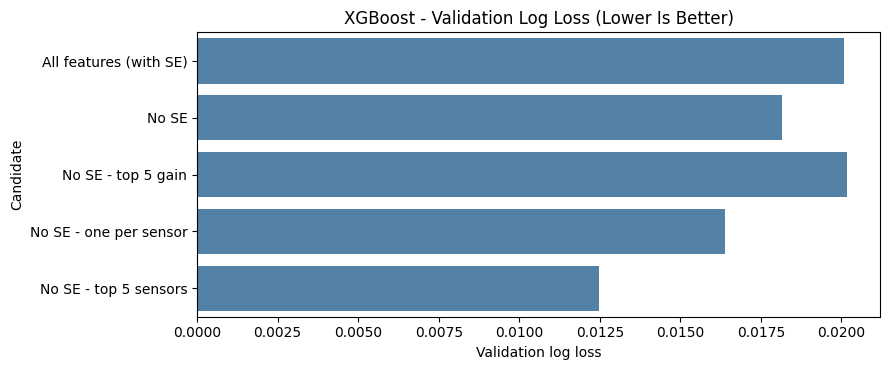

In [11]:
from sklearn.metrics import log_loss

# ==================================================
# XGBOOST - FIVE CANDIDATES, VALIDATION ONLY
# ==================================================

xgb_models = {
    "All features (with SE)": xgb_all,
    "No SE": xgb_no_se,
}
xgb_validation_rows = []

for candidate, columns in feature_sets.items():
    if candidate not in xgb_models:
        model = make_xgb()  # New model, no previous trees.
        model.fit(
            X_train[columns], y_train,
            eval_set=[(X_train[columns], y_train),
                      (X_val[columns], y_val)],
            verbose=False
        )
        xgb_models[candidate] = model

    model = xgb_models[candidate]
    val_pred = model.predict(X_val[columns])
    val_prob = model.predict_proba(X_val[columns])
    xgb_validation_rows.append({
        "Candidate": candidate,
        "Features": len(columns),
        "Validation accuracy": accuracy_score(y_val, val_pred),
        "Validation macro F1": f1_score(y_val, val_pred, average="macro"),
        "Validation log loss": log_loss(y_val, val_prob, labels=[0, 1, 2]),
    })

xgb_validation = pd.DataFrame(xgb_validation_rows)
display(xgb_validation.round(4))

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(data=xgb_validation,
            x="Validation log loss", y="Candidate", color="steelblue", ax=ax)
ax.set_title("XGBoost - Validation Log Loss (Lower Is Better)")
plt.tight_layout()
plt.show()


## 8. Evaluation and comparison

Compare the same five feature sets with **both models**. Model choices and ridge penalties use training/validation data, not test results.

All XGBoost candidates previously reached 100% validation accuracy in this split. The validation set has just seven operating configurations, so this does **not** imply perfect generalization. An earlier notebook version also inspected test performance; the test is therefore no longer strictly untouched.

### 8.1 Ridge ordinal regression: assumptions and diagnostics

The leakage labels are ordered (0 < 1 < 2). We assume cycles were collected independently under controlled conditions at a reputable institution, although repeated runs on one rig may share effects.

We check **constant columns, multicollinearity, numerical rank and ordinal separation** separately for each candidate set. The shared-slope (proportional-odds) and linear-logit assumptions remain model assumptions, not established by these screens. Ridge helps stabilize separation and correlated coefficients.

For ridge OLR, training-constant columns must be excluded. Thus the OLR feature count can be smaller than XGBoost's count for the *same candidate set*.

In [12]:
from scipy.optimize import linprog
from sklearn.preprocessing import StandardScaler

# ==================================================
# OLR DIAGNOSTICS - EACH OF THE FIVE CANDIDATE SETS
# ==================================================

def ordinal_separation_status(X_array, labels):
    """Can one ordered linear score strictly separate 0, 1 and 2?"""
    X_design = np.column_stack([np.ones(len(X_array)), X_array])
    y_array = np.asarray(labels)
    d = X_design.shape[1]

    x0 = X_design[y_array == 0]
    x1 = X_design[y_array == 1]
    x2 = X_design[y_array == 2]

    # Unknowns are (linear score coefficients, second threshold).
    A = np.vstack([
        np.column_stack([x0, np.zeros(len(x0))]),
        np.column_stack([-x1, np.zeros(len(x1))]),
        np.column_stack([x1, -np.ones(len(x1))]),
        np.column_stack([-x2, np.ones(len(x2))]),
        np.r_[np.zeros(d), -1.0][None, :]
    ])
    b = -np.ones(A.shape[0])
    b[-1] = -2.0

    solution = linprog(
        c=np.zeros(d + 1),
        A_ub=A, b_ub=b,
        bounds=[(None, None)] * (d + 1),
        method="highs"
    )
    if solution.success:
        return "Yes"
    if solution.status == 2:
        return "No"
    return "Inconclusive"

olr_columns = {}  # Nonconstant features for each set
olr_diagnostic_rows = []

for candidate, columns in feature_sets.items():
    retained = [c for c in columns if X_train[c].nunique(dropna=False) > 1]
    removed = sorted(set(columns) - set(retained))
    olr_columns[candidate] = retained

    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(X_train[retained].astype(float))
    assert np.isfinite(x_train_scaled).all()

    corr = pd.DataFrame(x_train_scaled).corr().abs().to_numpy()
    high_corr = np.triu(corr > 0.95, k=1).sum()
    singular_values = np.linalg.svd(x_train_scaled, compute_uv=False)
    condition_number = (singular_values[0] / singular_values[-1]
                        if singular_values[-1] > 0 else np.inf)

    olr_diagnostic_rows.append({
        "Candidate": candidate,
        "Original": len(columns),
        "OLR features": len(retained),
        "Constants removed": len(removed),
        "Rank": np.linalg.matrix_rank(x_train_scaled),
        "|r| > 0.95 pairs": int(high_corr),
        "Condition number": condition_number,
        "Ordinal separation": ordinal_separation_status(
            x_train_scaled, y_train.to_numpy()
        ),
    })

olr_diagnostics = pd.DataFrame(olr_diagnostic_rows)
display(olr_diagnostics.round(2))

print("\nRemoved constant columns by candidate:")
for candidate, columns in feature_sets.items():
    removed = sorted(set(columns) - set(olr_columns[candidate]))
    print(f"{candidate}: {removed or 'none'}")

print("\nNOTE: Separation and correlation checks do not verify proportional odds.")


,Candidate,Original,OLR features,Constants removed,Rank,|r| > 0.95 pairs,Condition number,Ordinal separation
0,All features (with SE),68,64,4,64,442,14769.99,Yes
1,No SE,64,61,3,61,433,14439.13,Yes
2,No SE - top 5 gain,5,5,0,5,1,29.44,No
3,No SE - one per sensor,16,16,0,16,11,137.97,No
4,No SE - top 5 sensors,5,5,0,5,0,22.92,No



Removed constant columns by candidate:
All features (with SE): ['FS1_min', 'PS2_min', 'PS3_min', 'SE_min']
No SE: ['FS1_min', 'PS2_min', 'PS3_min']
No SE - top 5 gain: none
No SE - one per sensor: none
No SE - top 5 sensors: none

NOTE: Separation and correlation checks do not verify proportional odds.


### 8.2 Ridge ordinal regression: train and validate

Fit `mord.LogisticAT` on **each of the five feature sets** using training data only. Standardize features using training statistics. Choose `alpha` separately for each set using validation macro F1, then accuracy and log loss to break ties.

`LogisticAT` is an L2-regularized, all-threshold ordinal logistic classifier. Its objective is not identical to unregularized ordered-logit maximum likelihood.

If needed, install once in the notebook environment: `%pip install mord`.

In [13]:
import mord

# ==================================================
# RIDGE OLR - FIVE CANDIDATES, VALIDATION ONLY
# ==================================================

alpha_grid = [0.1, 1, 10, 100]
olr_models = {}
olr_scalers = {}
olr_validation_rows = []
olr_alpha_history = []

for candidate, columns in olr_columns.items():
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(X_train[columns].astype(float))
    val_scaled = scaler.transform(X_val[columns].astype(float))

    candidates_for_alpha = []
    for alpha in alpha_grid:
        model = mord.LogisticAT(alpha=alpha, max_iter=3000)
        model.fit(train_scaled, y_train.to_numpy())

        if not (np.isfinite(model.coef_).all() and
                np.isfinite(model.theta_).all()):
            raise ValueError(f"Non-finite OLR parameters: {candidate}, alpha={alpha}")

        prediction = model.predict(val_scaled)
        probabilities = model.predict_proba(val_scaled)
        row = {
            "Candidate": candidate,
            "OLR features": len(columns),
            "Alpha": alpha,
            "Validation accuracy": accuracy_score(y_val, prediction),
            "Validation macro F1": f1_score(y_val, prediction, average="macro"),
            "Validation log loss": log_loss(
                y_val, probabilities, labels=[0, 1, 2]
            ),
        }
        candidates_for_alpha.append((row, model))
        olr_alpha_history.append(row)

    # Select regularization strength using validation only.
    best_row, best_model = sorted(
        candidates_for_alpha,
        key=lambda item: (-item[0]["Validation macro F1"],
                          -item[0]["Validation accuracy"],
                          item[0]["Validation log loss"],
                          -item[0]["Alpha"])
    )[0]

    olr_models[candidate] = best_model
    olr_scalers[candidate] = scaler
    olr_validation_rows.append(best_row)

olr_validation = pd.DataFrame(olr_validation_rows)

print("RIDGE OLR - VALIDATION RESULTS")
display(olr_validation.round(4))
print("\nAlpha selection details (all fits):")
display(pd.DataFrame(olr_alpha_history).round(4))


RIDGE OLR - VALIDATION RESULTS


,Candidate,OLR features,Alpha,Validation accuracy,Validation macro F1,Validation log loss
0,All features (with SE),64,10.0,1.0000,1.0000,0.2512
1,No SE,61,10.0,0.9952,0.9952,0.2671
2,No SE - top 5 gain,5,0.1,0.9810,0.9809,0.1410
3,No SE - one per sensor,16,0.1,0.9619,0.9618,0.1132
4,No SE - top 5 sensors,5,1.0,0.9476,0.9472,0.2310



Alpha selection details (all fits):


,Candidate,OLR features,Alpha,Validation accuracy,Validation macro F1,Validation log loss
0,All features (with SE),64,0.1,0.9905,0.9905,0.0279
1,All features (with SE),64,1.0,0.9857,0.9857,0.0810
2,All features (with SE),64,10.0,1.0000,1.0000,0.2512
3,All features (with SE),64,100.0,0.9238,0.9234,0.5947
4,No SE,61,0.1,0.9905,0.9905,0.0313
5,No SE,61,1.0,0.9857,0.9857,0.0852
6,No SE,61,10.0,0.9952,0.9952,0.2671
7,No SE,61,100.0,0.8810,0.8800,0.6361
8,No SE - top 5 gain,5,0.1,0.9810,0.9809,0.1410
9,No SE - top 5 gain,5,1.0,0.9667,0.9667,0.3393


### 8.3 Validation comparison

Compare XGBoost and OLR on the same five feature sets. Counts can differ only because OLR excludes constant training columns.

In [14]:
# ==================================================
# XGBOOST VS. RIDGE OLR - VALIDATION COMPARISON
# ==================================================

xgb_view = xgb_validation.copy()
xgb_view["Model"] = "XGBoost"
xgb_view = xgb_view.rename(columns={"Features": "Used features"})

olr_view = olr_validation.copy()
olr_view["Model"] = "Ridge OLR"
olr_view = olr_view.rename(columns={"OLR features": "Used features"})

validation_comparison = pd.concat([
    xgb_view[["Candidate", "Model", "Used features", "Validation accuracy",
              "Validation macro F1", "Validation log loss"]],
    olr_view[["Candidate", "Model", "Used features", "Validation accuracy",
              "Validation macro F1", "Validation log loss"]]
], ignore_index=True)

validation_comparison["Candidate"] = pd.Categorical(
    validation_comparison["Candidate"],
    categories=list(feature_sets), ordered=True
)
validation_comparison = validation_comparison.sort_values(
    ["Candidate", "Model"]
).reset_index(drop=True)
display(validation_comparison.round(4))


,Candidate,Model,Used features,Validation accuracy,Validation macro F1,Validation log loss
0,All features (with SE),Ridge OLR,64,1.0000,1.0000,0.2512
1,All features (with SE),XGBoost,68,1.0000,1.0000,0.0201
2,No SE,Ridge OLR,61,0.9952,0.9952,0.2671
3,No SE,XGBoost,64,1.0000,1.0000,0.0182
4,No SE - top 5 gain,Ridge OLR,5,0.9810,0.9809,0.1410
5,No SE - top 5 gain,XGBoost,5,1.0000,1.0000,0.0202
6,No SE - one per sensor,Ridge OLR,16,0.9619,0.9618,0.1132
7,No SE - one per sensor,XGBoost,16,1.0000,1.0000,0.0164
8,No SE - top 5 sensors,Ridge OLR,5,0.9476,0.9472,0.2310
9,No SE - top 5 sensors,XGBoost,5,1.0000,1.0000,0.0125


### 8.4 Test comparison

Evaluate the **five predefined sets with both models** on the same held-out operating configurations. This is a fixed comparison, **not** a search for the best test score. The test set was already inspected in an earlier notebook version, so interpret these results as exploratory rather than fully untouched confirmation.

,Candidate,Model,Features used,Test accuracy,Test macro F1
0,All features (with SE),XGBoost,68,0.9855,0.9857
1,All features (with SE),Ridge OLR,64,0.9903,0.9905
2,No SE,XGBoost,64,0.9903,0.9905
3,No SE,Ridge OLR,61,0.9903,0.9905
4,No SE - top 5 gain,XGBoost,5,0.9710,0.9713
5,No SE - top 5 gain,Ridge OLR,5,0.9710,0.9712
6,No SE - one per sensor,XGBoost,16,0.9807,0.9810
7,No SE - one per sensor,Ridge OLR,16,0.9710,0.9714
8,No SE - top 5 sensors,XGBoost,5,0.9758,0.9762
9,No SE - top 5 sensors,Ridge OLR,5,0.9275,0.9285


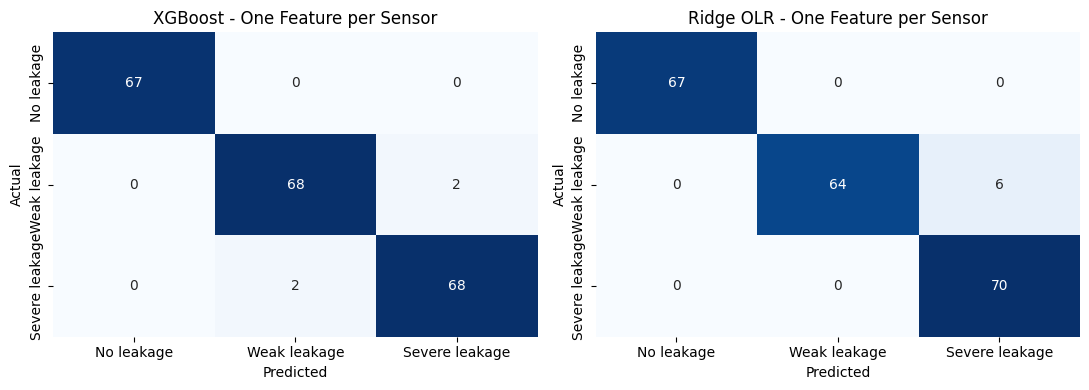

In [15]:
# ==================================================
# TEST - ALL FIVE PREDEFINED SETS, BOTH MODELS
# ==================================================

test_rows = []
test_predictions = {}
class_labels = ["No leakage", "Weak leakage", "Severe leakage"]

for candidate, columns in feature_sets.items():
    # XGBoost
    xgb_pred = xgb_models[candidate].predict(X_test[columns])
    test_predictions[(candidate, "XGBoost")] = xgb_pred
    test_rows.append({
        "Candidate": candidate,
        "Model": "XGBoost",
        "Features used": len(columns),
        "Test accuracy": accuracy_score(y_test, xgb_pred),
        "Test macro F1": f1_score(y_test, xgb_pred, average="macro"),
    })

    # Ridge OLR: same candidate, minus training-constant columns
    columns_olr = olr_columns[candidate]
    x_test_scaled = olr_scalers[candidate].transform(
        X_test[columns_olr].astype(float)
    )
    olr_pred = olr_models[candidate].predict(x_test_scaled)
    test_predictions[(candidate, "Ridge OLR")] = olr_pred
    test_rows.append({
        "Candidate": candidate,
        "Model": "Ridge OLR",
        "Features used": len(columns_olr),
        "Test accuracy": accuracy_score(y_test, olr_pred),
        "Test macro F1": f1_score(y_test, olr_pred, average="macro"),
    })

test_comparison = pd.DataFrame(test_rows)
display(test_comparison.round(4))

# Two confusion matrices for one pre-specified, sensor-diverse reduced set.
example_candidate = "No SE - one per sensor"
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, model_name in zip(axes, ["XGBoost", "Ridge OLR"]):
    predictions = test_predictions[(example_candidate, model_name)]
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1, 2])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=ax)
    ax.set_title(f"{model_name} - One Feature per Sensor")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## 9. Model interpretability

Compare which **physical sensors** remain useful without `SE`. Gain and SHAP explain model behavior, not the physical cause of leakage. Correlated features can share or compete for importance.

### 9.1 XGBoost feature importance (without SE)

Rank the non-SE model's features using the training-set total gain. Show the highest-gain feature within each sensor.

,Feature,Total gain,Sensor
12,FS1_mean,10571.04,FS1
10,EPS1_min,1724.52,EPS1
11,EPS1_max,1494.09,EPS1
8,EPS1_mean,1194.81,EPS1
13,FS1_std,906.42,FS1
22,PS1_max,593.79,PS1
60,VS1_max,571.24,VS1
58,VS1_std,272.66,VS1
26,PS3_mean,166.89,PS3
0,CE_mean,163.88,CE


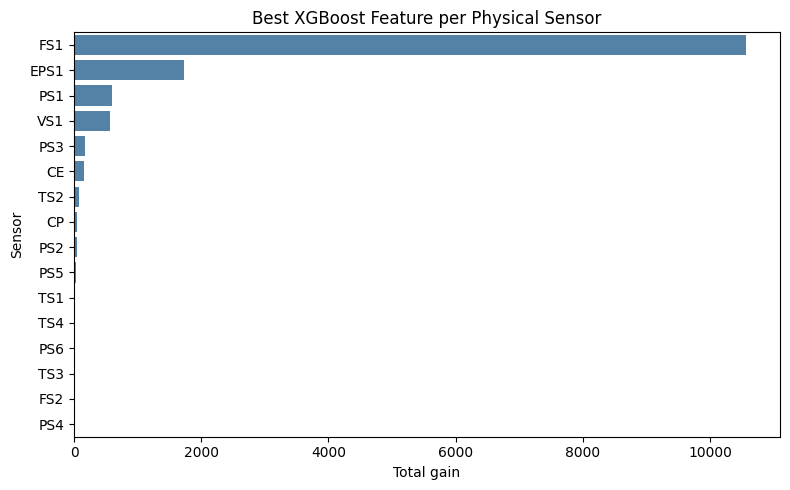

In [16]:
# ==================================================
# XGBOOST TOTAL GAIN - PHYSICAL SENSORS ONLY
# ==================================================

physical_importance = pd.DataFrame({
    "Feature": nonconstant_no_se,
    "Total gain": [no_se_gain.get(f, 0.0) for f in nonconstant_no_se]
})
physical_importance["Sensor"] = physical_importance["Feature"].str.rsplit(
    "_", n=1
).str[0]
physical_importance = physical_importance.sort_values(
    "Total gain", ascending=False
)

display(physical_importance.head(15).round(2))

best_sensor_gain = (
    physical_importance.loc[
        physical_importance.groupby("Sensor")["Total gain"].idxmax()
    ]
    .sort_values("Total gain", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=best_sensor_gain, x="Total gain", y="Sensor",
            color="steelblue", ax=ax)
ax.set_title("Best XGBoost Feature per Physical Sensor")
plt.tight_layout()
plt.show()


### 9.2 SHAP for one feature per sensor

Explain the predefined 16-feature XGBoost model. This view avoids multiple statistics from the same sensor, but correlations **between sensors** can still affect SHAP attribution.

c:\Users\Admin\Desktop\צבא\הכשרה דאטא סיינס\4. DS Pipeline\ML - Leakage classification\DS Project---ML-classification-\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Mean |SHAP|
FS1_mean,1.992
EPS1_min,0.716
PS1_max,0.474
TS2_mean,0.355
VS1_max,0.338
PS3_mean,0.167
CP_min,0.114
PS5_mean,0.088
TS1_std,0.081
PS4_mean,0.074


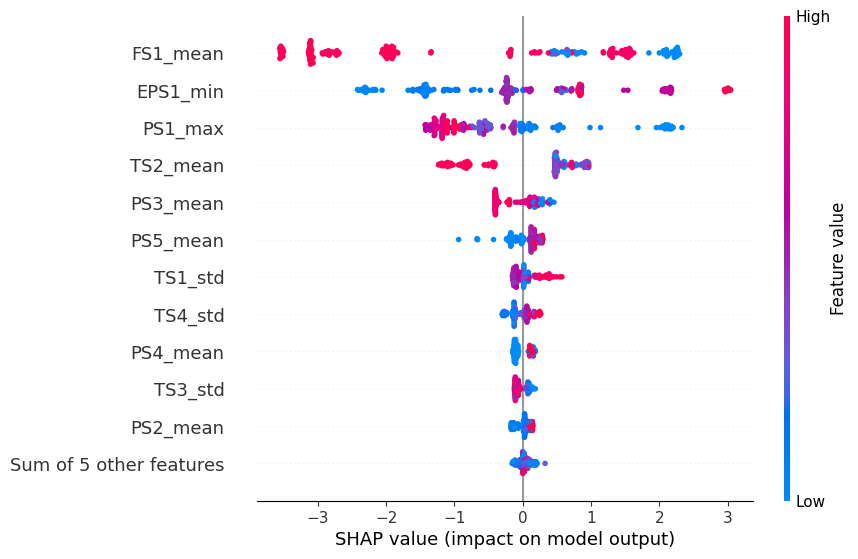

In [17]:
# ==================================================
# SHAP - THE PREDEFINED ONE-FEATURE-PER-SENSOR MODEL
# ==================================================

import shap

shap_candidate = "No SE - one per sensor"
shap_columns = feature_sets[shap_candidate]
shap_model = xgb_models[shap_candidate]

shap_explanation = shap.TreeExplainer(shap_model)(X_test[shap_columns])
assert shap_explanation.values.shape == (len(X_test), len(shap_columns), 3)

shap_global = np.abs(shap_explanation.values).mean(axis=(0, 2))
shap_ranking = pd.Series(shap_global, index=shap_columns).sort_values(
    ascending=False
)
display(shap_ranking.rename("Mean |SHAP|").to_frame().round(3))

shap.plots.beeswarm(shap_explanation[:, :, 2], max_display=12)


### 9.3 Ridge OLR coefficients (same sensor set)

OLR coefficients show the direction of the **shared linear score** after standardizing the selected features. They are not directly comparable in size to SHAP values, especially when sensors are correlated.

,Standardized OLR coefficient
PS1_max,-13.511
PS2_mean,-11.665
EPS1_min,10.275
PS3_mean,-9.590
TS2_mean,-9.008
FS1_mean,-7.098
CP_min,-3.869
PS5_mean,3.349
FS2_std,-1.456
PS4_mean,1.287


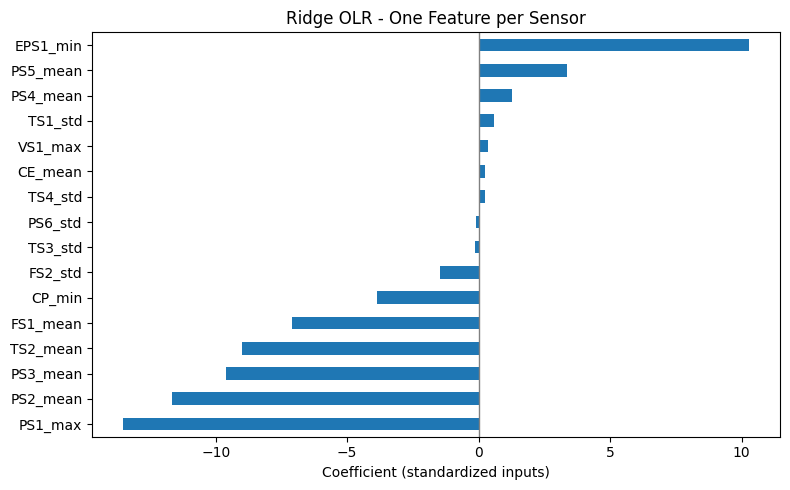

In [18]:
# ==================================================
# RIDGE OLR - STANDARDIZED COEFFICIENTS
# ==================================================

coef_candidate = "No SE - one per sensor"
coef_features = olr_columns[coef_candidate]
coef_values = olr_models[coef_candidate].coef_

olr_coefficients = pd.Series(
    coef_values, index=coef_features, name="Standardized OLR coefficient"
).sort_values(key=np.abs, ascending=False)
display(olr_coefficients.to_frame().round(3))

fig, ax = plt.subplots(figsize=(8, 5))
olr_coefficients.sort_values().plot.barh(ax=ax)
ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Ridge OLR - One Feature per Sensor")
ax.set_xlabel("Coefficient (standardized inputs)")
plt.tight_layout()
plt.show()


## 10. Summary and recommendations

After running the cells, report: (1) whether excluding derived `SE` affects accuracy, (2) whether five features or one per sensor are sufficient, and (3) how XGBoost and ridge OLR compare on each set. Perfect validation accuracy does not prove perfect generalization.

## 11. Presentation (optional)

Present the five candidate sets, validation results for both models, and the fixed test comparison. State that all results come from controlled test-rig conditions.